In [8]:
pip install seaborn

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.3 MB 134.2 MB/s eta 0:00:01
   ------- -------------------------------- 1.8/9.3 MB 5.1 MB/s eta 0:00:02
   ---------- ----------------------------- 2.4/9.3 MB 4.0 MB/s eta 0:00:02
   ------------ --------------------------- 2.9/9.3 MB 3.5 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.3 MB 3.2 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.3 MB 3.1 MB/s eta 0:00:02
   ------------------- -------------------- 4.5/9.3 MB 3.0 MB/s eta 0:00:02
   --------------------- ------------------ 5.0/9.3 MB 2.9 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.3 MB 2.8 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.3 MB 2.8 MB/s eta 0:00:02
   -------------------------- ------------- 6.3/9.3 MB 2.7 MB/s eta 0:00:02
   ----------------------------- ---------- 6.8/9.3 MB 2.6 MB/s eta 0:00:01
   --------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [12]:
# 2. HANDLING MISSING VALUES
# ==========================================
print("\n--- Checking Missing Values ---")
print(df.isnull().sum())


--- Checking Missing Values ---
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [13]:
# Impute numerical columns with their median
for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].fillna(df[col].median())

# Impute categorical columns with their mode
for col in df.select_dtypes(include=['object', 'category']).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

C:\Users\user\AppData\Local\Temp\ipykernel_11104\4203210551.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object', 'category']).columns:


In [14]:
# Drop rows where critical columns are still missing
df = df.dropna(subset=['pickup', 'fare'])
print("Missing values after cleaning:", df.isnull().sum().sum())

Missing values after cleaning: 0


In [16]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


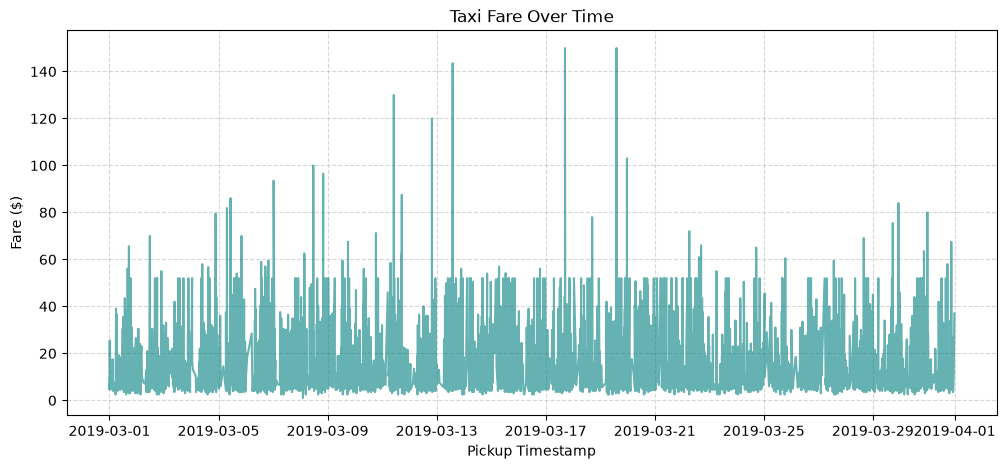

In [19]:
import matplotlib.pyplot as plt
#3. VISUALIZATIONS USING MATPLOTLIB / PANDAS
# ==========================================

# A. Line Chart: Fare Over Time
df['pickup'] = pd.to_datetime(df['pickup'])
df_sorted = df.sort_values('pickup')

plt.figure(figsize=(12, 5))
plt.plot(df_sorted['pickup'], df_sorted['fare'], color='teal', alpha=0.6)
plt.title('Taxi Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

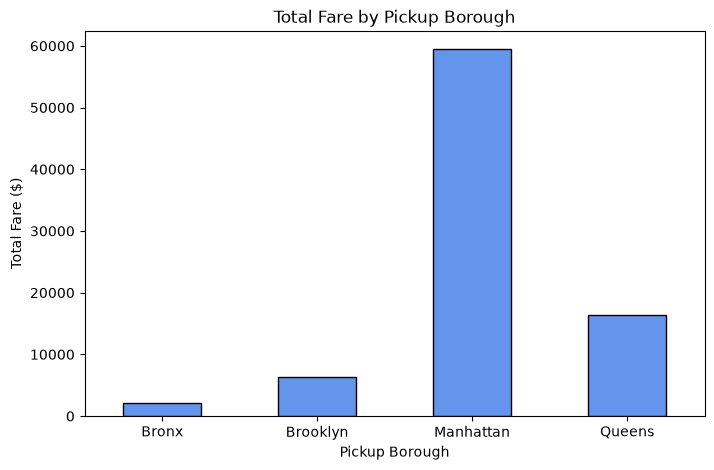

In [20]:
# B. Bar Chart: Total Fare by Pickup Borough
borough_fare = df.groupby('pickup_borough')['fare'].sum()
plt.figure(figsize=(8, 5))
borough_fare.plot(kind='bar', color='cornflowerblue', edgecolor='black')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare ($)')
plt.xticks(rotation=0)
plt.show()

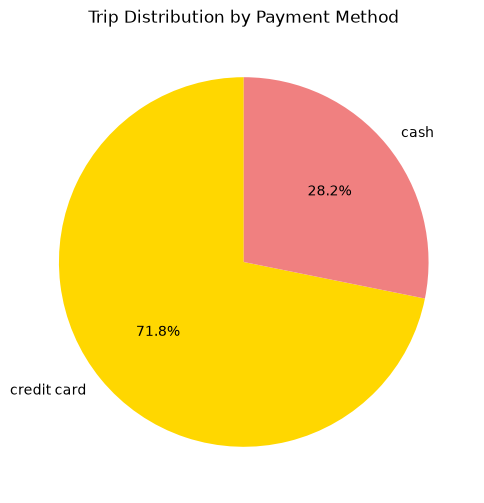

In [21]:
# C. Pie Chart: Trip Distribution by Payment Method
payment_counts = df['payment'].value_counts()
plt.figure(figsize=(6, 6))
payment_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['gold', 'lightcoral', 'lightskyblue', 'lightgreen'])
plt.title('Trip Distribution by Payment Method')
plt.ylabel('')
plt.show()

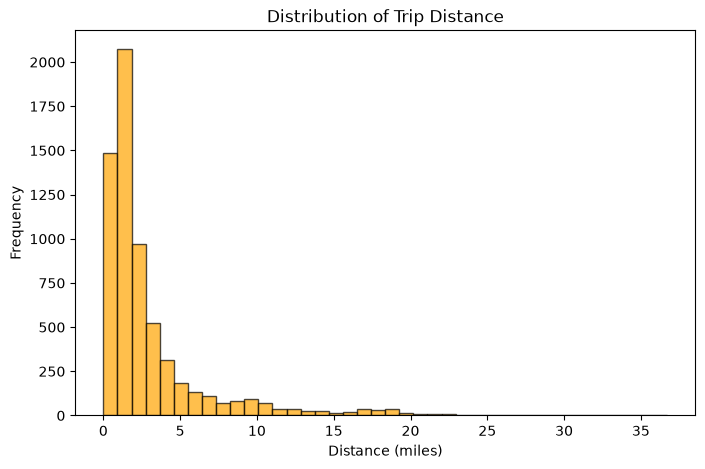

In [22]:
# D. Histogram: Distribution of Distance
plt.figure(figsize=(8, 5))
plt.hist(df['distance'], bins=40, color='orange', edgecolor='black', alpha=0.7)
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance (miles)')
plt.ylabel('Frequency')
plt.show()

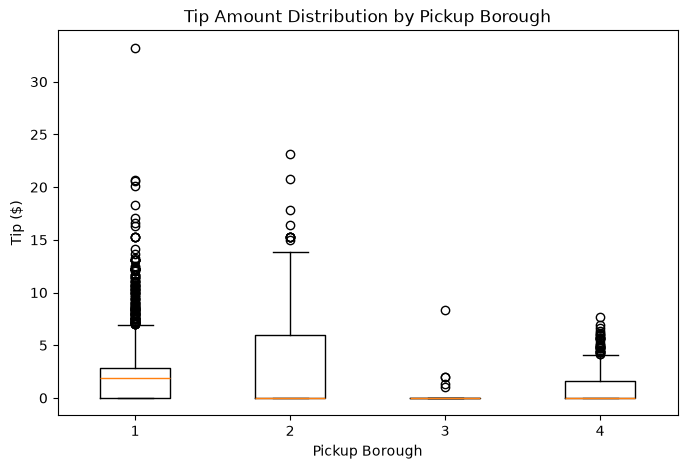

In [24]:
# E. Box Plot: Tip Amount by Pickup Borough
plt.figure(figsize=(8, 5))
plt.boxplot([df[df['pickup_borough'] == b]['tip'].dropna() for b in df['pickup_borough'].dropna().unique()],
            label=df['pickup_borough'].dropna().unique())
plt.title('Tip Amount Distribution by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip ($)')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_11104\1128858802.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='pickup_borough', data=df, palette='Set2')


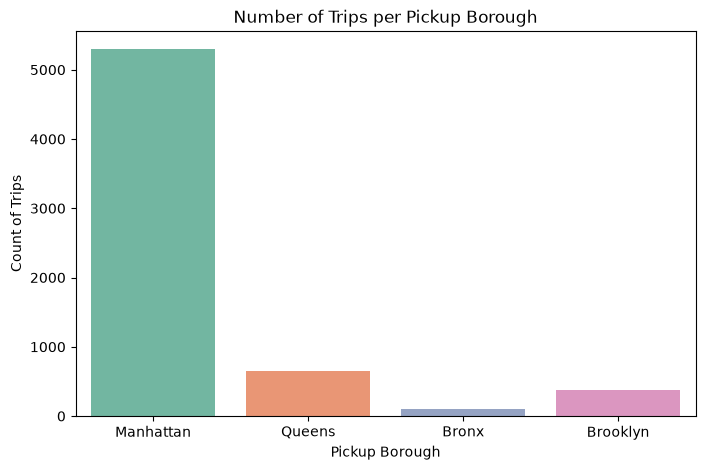

In [25]:
# 4. VISUALIZATIONS USING SEABORN
# ==========================================

# A. Count Plot: Number of Trips in Each Pickup Borough
plt.figure(figsize=(8, 5))
sns.countplot(x='pickup_borough', data=df, palette='Set2')
plt.title('Number of Trips per Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Count of Trips')
plt.show()

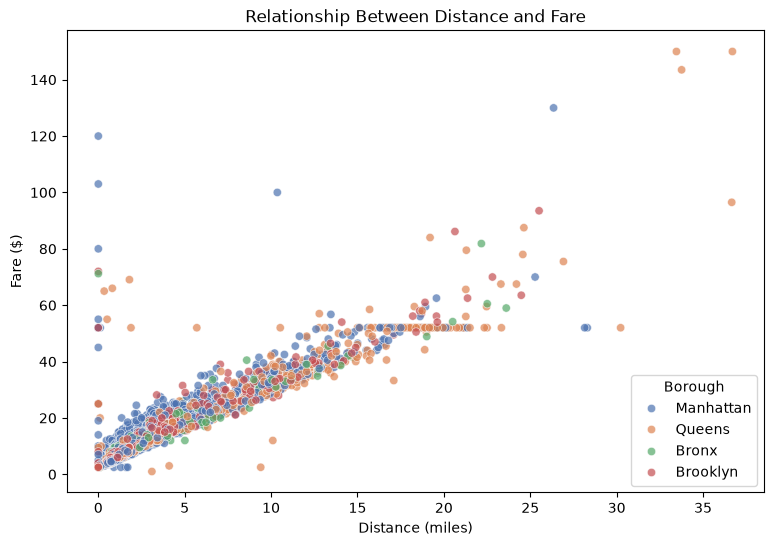

In [26]:
# B. Scatter Plot: Distance vs. Fare colored by Pickup Borough
plt.figure(figsize=(9, 6))
sns.scatterplot(x='distance', y='fare', hue='pickup_borough', data=df, alpha=0.7, palette='deep')
plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance (miles)')
plt.ylabel('Fare ($)')
plt.legend(title='Borough')
plt.show()

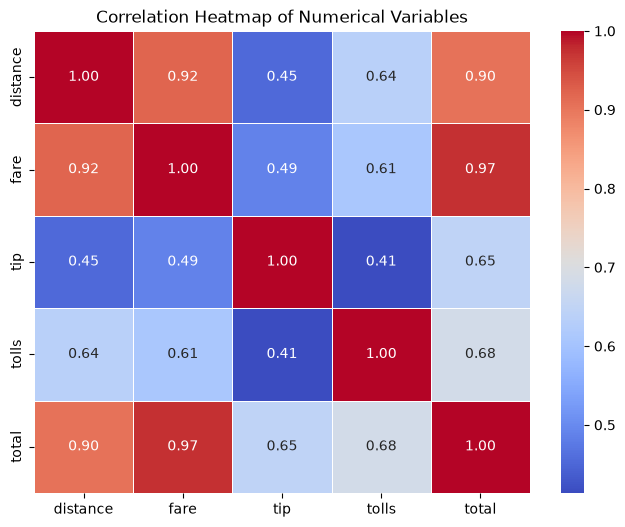

In [27]:
#C. Heatmap: Correlation Matrix
plt.figure(figsize=(8, 6))
numerical_cols = ['distance', 'fare', 'tip', 'tolls', 'total']
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

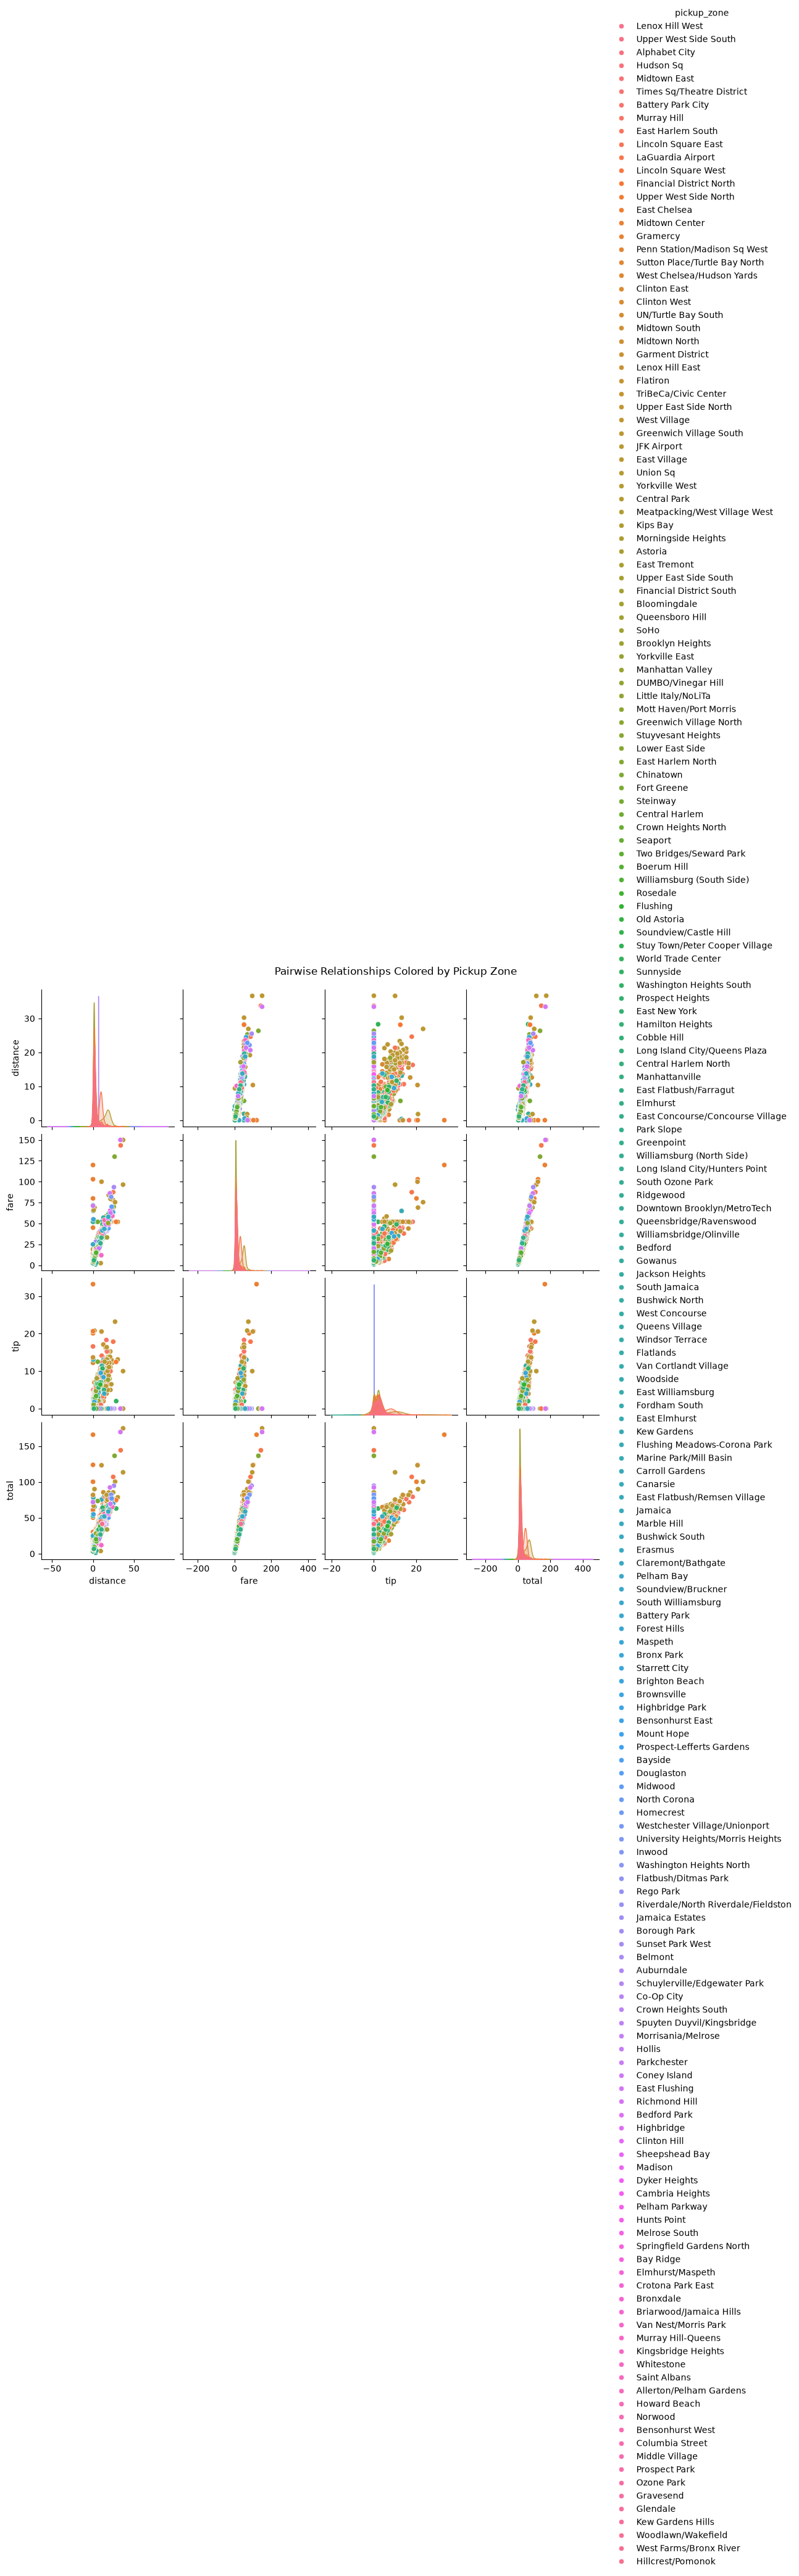

In [28]:
# D. Pair Plot: Pairwise Relationships colored by Pickup Zone
pair_df = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna()
sns.pairplot(pair_df, hue='pickup_zone', diag_kind='kde', height=2.5)
plt.suptitle('Pairwise Relationships Colored by Pickup Zone', y=1.02)
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_11104\3581073613.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='payment', y='fare', data=df, palette='muted', inner='quartile')


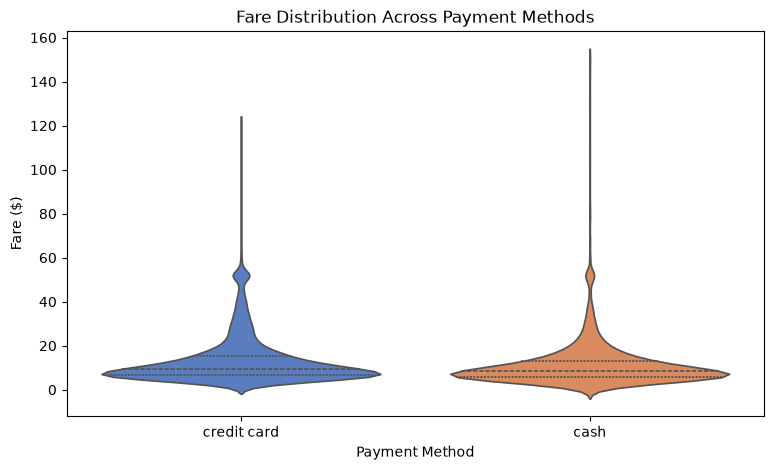

In [29]:
# E. Violin Plot: Fare Distribution by Payment Method
plt.figure(figsize=(9, 5))
sns.violinplot(x='payment', y='fare', data=df, palette='muted', inner='quartile')
plt.title('Fare Distribution Across Payment Methods')
plt.xlabel('Payment Method')
plt.ylabel('Fare ($)')
plt.show()